In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os,sys
from copy import deepcopy

#we use inverse slope, 1/k, whereas most of the literature uses k. This is because we want to avoid division in the sigmoid function
from auxillaryFunctions import *
def genFastSynapse(TS,baseConductance,conductanceGain = 10):
    #for the synapses to work properly you need to know TS
    #This lets the conductance go instantly from 0 to 1
    
    AMPA = {"name":None,
                "ion":None,
            "Erev": 0,#NOTE: its worth keeping in mind that reversal potential is a property of a neuron, not its synapse, so we shoul probably move this
            "conductance": baseConductance,
            "current":0,
            "CaCurrent": 0,
            "gates":{
            "vGate1":genOpenGate(),
            "vGate2":genOpenGate(),
            "CaGate":genOpenGate(),
            "spikeGate":genSynapseGate(7,TS)}} #decay is about 7ms for AMPA and GABA, though it can vary a lot, tbh this could be a random variable
    
    for key,val in genDefaultPlasticSynapseData(conductanceGain).items():
        AMPA[key] = val

    return AMPA


def genGABA(TS,baseConductance,conductanceGain):
    GABA = genFastSynapse(TS,baseConductance,conductanceGain)
    GABA["name"] = "AMPAR"
    GABA["ion"] = "Anion"
    GABA["Erev"] = -80
    return GABA




e:\code\pythonCPPtesting.ipynb\auxillaryFunctions.py:48: RuntimeWarning: overflow encountered in exp
  return minOp +  (1.0-minOp)/(1.0 + np.exp((h-z)*kInv))


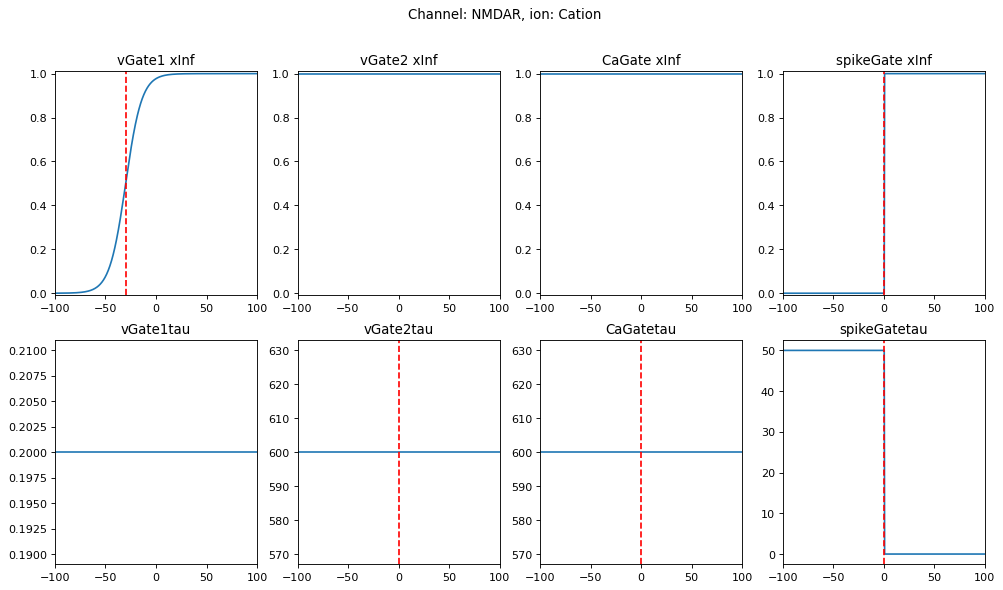

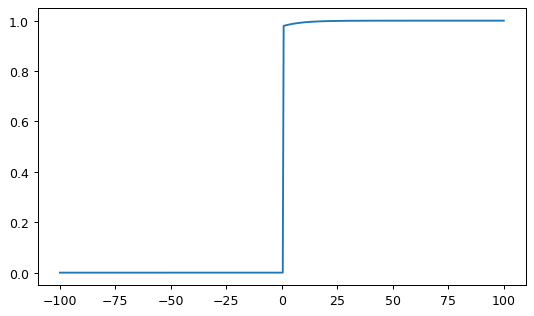

In [17]:
def examineGate(gateInfo,valRange,gateName,ax=None):
    gRange = [min(valRange),max(valRange)]
    vH,vK = gateInfo["vHalf"],gateInfo["vKi"]
    tau0,tau1,th,tkInv = gateInfo["tau0"],gateInfo["tau1"],gateInfo["th"],gateInfo["tkInv"]
    minOp = gateInfo["minOpenness"]
    

    xInf = sigmoid(valRange,vH,vK,minOp)
    tau = tau0 + tau1*sigmoid(valRange,th,tkInv,0)
    if ax == None:
        fig,ax = plt.subplots(2,1,figsize=(8,6), dpi=100)
    else:
        ax[0].plot(valRange,xInf)
        ax[0].axvline(vH,color="r",linestyle="--")
        ax[0].set_title(f"{gateName} xInf")
        ax[0].set_xlim(gRange)
        #x[0].set_ylabel("Gate opening")
        ax[0].set_ylim(-0.01,1.01)

        ax[1].plot(valRange,tau)
        ax[1].axvline(th,color="r",linestyle="--")
        ax[1].set_title(f"{gateName}tau")
        #ax[1].set_ylabel("Time constant (ms)")
        ax[1].set_xlim(gRange)
    
    return xInf

def examineChannel(channel,s0=-100,s1=100):
    fig,ax = plt.subplots(2,4,figsize=(15,8), dpi=80)
    fig.suptitle(f"Channel: {channel['name']}, ion: {channel['ion']}")
    valRange = np.linspace(s0,s1,501)
    netOpening = 1
    for i,(gate,gateData) in enumerate(channel["gates"].items()):
        exponent = gateData["exponent"]
        xInf = examineGate(gateData,valRange,gate,[ax[0,i],ax[1,i]])
        netOpening *= xInf**exponent

    fig,ax = plt.subplots(1,1,dpi=90,figsize=[7,4])
    ax.plot(valRange,netOpening)

Nav1x6 = {"name":"Nav1x6",
            "ion":"Na",
           "Erev": 90,
           "conductance": 20,
           "CaCurrent": 1, #its not a Ca current, this is just for testing (although, many cation channels will let in a tiny bit of Ca)
           "gates":{
           "vGate1":genGate(-40,-1/4,0.2,2,-20,-1/5,exponent=3,minOpenness=0.0), #inactivation, slow to fast
           "vGate2":genGate(-30,1/4,0.1,0.1,-1000,100), #activation , slow to fast 
           "CaGate":genOpenGate(),
           "spikeGate":genOpenGate()}}

Kv2x2 = {"name":"Kv2x2",
        "ion":"K",
           "Erev": -90,
           "conductance": 20,
           "CaCurrent": 0,
           "gates":{
           "vGate1":genGate(-30,1/10,1,5,-20,-1/10,exponent=1),
           "vGate2":genGate(-30,-1/10,1,5,-46,1/20,exponent=1),
           "CaGate":genOpenGate(),
           "spikeGate":genOpenGate()}}


def genSynapseGate(xt1,TS):
    xt0 = TS
    xt1 = xt1-xt0
    return genGate(0.5,100,xt0,xt1,0.5,-100)

def genNMDA(TS):
    #for the synapses to work properly you need to know TS
    #This lets the conductance go instantly from 0 to 1
    #I wonder if this will cause instability?
    #If this doesnt work I'll have to implement a more expensive second order ODE
    timeScale = 50
    NMDA = {"name":"NMDAR",
                "ion":"Cation",
            "Erev": 0,
            "conductance": 10,
            "current":0,
            "CaCurrent": 1,
            "gates":{
            "vGate1":genGate(-30,1/8,0.1,0.1,-1000,100),
            "vGate2":genOpenGate(),
            "CaGate":genOpenGate(),
            "spikeGate":genSynapseGate(timeScale,TS)}}
    return NMDA


TS = 0.01
nmda = genNMDA(TS)
examineChannel(nmda,-100,100)

Text(0.5, 1.0, 'gating value')

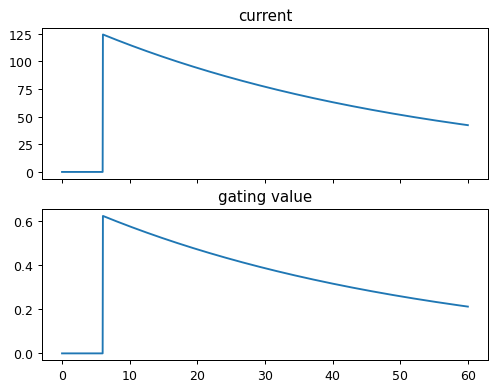

In [18]:
#need to be able to test this in a reduced simulation 
def temporalChannelTest(channel,duration,TS,vRamp=False,spikeInput=True):
    channel = deepcopy(channel)
    nIterations = int(duration/TS)
    voltages = -20*np.ones(nIterations)
    ind = int(0.1*nIterations)
    if vRamp:
        voltages[ind:ind+100] = np.linspace(-80,40,100)
    #voltages[ind+100::] = 40
    inputs = np.zeros(nIterations)
    # ind = int(nIterations/2)
    if spikeInput:
        inputs[ind:(ind+1)] = 1
    # ind = int(3*nIterations/4)
    # inputs[ind:(ind+1)] = 1

    currents = np.zeros(nIterations)
    gatingTotals = np.zeros(nIterations)
    Erev = channel["Erev"]
    g = channel["conductance"]
    tv=np.linspace(0,duration,nIterations)
    individualGates = [[] for _ in range(4)]
    for it in range(nIterations):
        gatingTotal = 1
        for gate,val in channel["gates"].items():
            gatingTotal *= (val["x"]**val["exponent"])

        V = voltages[it]
        I = -g*gatingTotal*(V-Erev) 
        currents[it]=I
        gatingTotals[it] = gatingTotal
        #update gates,
        #then update voltages
        gateDataMap = {"vGate1":V,"vGate2":V,"CaGate":0,"spikeGate":inputs[it]}

        for i,(gate,val) in enumerate(channel["gates"].items()):
            d = gateDataMap[gate]
            val["x"] = solveGate(val["x"],d,TS,val["vHalf"],val["vKi"],val["tau0"],val["tau1"],val["th"],val["tkInv"],val["minOpenness"])
            individualGates[i].append(val["x"])

    return currents,gatingTotals,tv,individualGates


currents,gatingTotals,tv,individualGates = temporalChannelTest(nmda,60,0.04,)
fig,ax = plt.subplots(2,1,dpi=90,sharex=True)
ax[0].plot(tv,currents)
ax[0].set_title("current")
ax[1].plot(tv,gatingTotals)
ax[1].set_title("gating value")


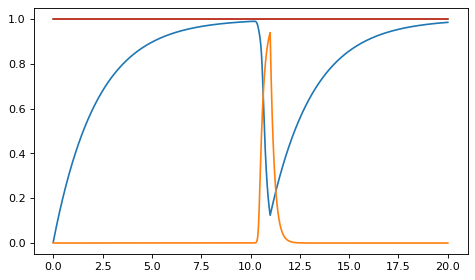

In [5]:
fig,ax = plt.subplots(1,1,dpi=80,figsize=[7,4])
for x in individualGates:
    ax.plot(tv,x)

In [6]:
TS = 0.1

def f(x,a,b):
    return -a*x + b

def plotSys(a,b,c):
    vals = []
    yvals = []
    x = 0.2
    y = 0.4
    nIterations = 1000
    # a = 1
    # b = 2
    # c = 2
    # d = -3
    for i in range(nIterations):
        if i == 500:
            x = 1
        x+=TS*f(x,a,b)
        y+=TS*f(y**2,c,x)
        vals.append(x)
        yvals.append(y)

    fig,ax = plt.subplots(1,3,figsize=(12,4),dpi=100)
    ax[0].plot(vals)
    ax[1].plot(yvals)
    ax[2].plot(vals,yvals)

from ipywidgets import interact
interact(plotSys,a=(0,1,0.01),b=(0,1,0.01),c=(0,1,0.01))

interactive(children=(FloatSlider(value=0.0, description='a', max=1.0, step=0.01), FloatSlider(value=0.0, desc…

<function __main__.plotSys(a, b, c)>

In [22]:
TS = 0.1


def plotSys(a,b,c):
    a=1/a
    vals = []
    filtVals = []
    zVals,spikeVals = [],[]
    nIterations = 100
    x = 1
    z = 1
    spike = 0
    for i in range(nIterations):
        spike = 0
        x -= TS*a*x 
        y = sigmoid(x,c,b,0)
        if y>0.99 and z == 1: 
            spike = 1
            z = 0
            
        vals.append(x)
        filtVals.append(y)
        zVals.append(z)
        spikeVals.append(spike)
        


    fig,ax = plt.subplots(1,3,figsize=(14,4),dpi=150)
    tv = np.linspace(0,int(nIterations*TS),nIterations)
    ax[0].plot(tv,vals)
    ax[1].plot(tv,filtVals)
    ax[2].plot(tv,spikeVals)


from ipywidgets import interact
interact(plotSys,a=(1,10,1),b=(-100,0,1),c=(0,1,0.01))

interactive(children=(IntSlider(value=5, description='a', max=10, min=1), IntSlider(value=-50, description='b'…

<function __main__.plotSys(a, b, c)>

In [26]:
TS = 0.1


def plotSys(a,b,c):
    a=1/a
    vals = []
    filtVals = []
    zVals,spikeVals = [],[]
    nIterations = 100
    x = 0
    z = 0

    for i in range(nIterations):
        spike = 0
        x -= TS*a*x 
        #y = sigmoid(x,c,b,0)
        if x<=0.37 and z == 1: 
            spike = 1
            z = 0
            
        vals.append(x)
        zVals.append(z)
        spikeVals.append(spike)

        if i in [49,50,51]:
            x=1
            z=1

        
    fig,ax = plt.subplots(1,3,figsize=(14,4),dpi=150)
    tv = np.linspace(0,int(nIterations*TS),nIterations)
    ax[0].plot(tv,vals)
    ax[1].plot(tv,zVals)
    ax[2].plot(tv,spikeVals)


from ipywidgets import interact
interact(plotSys,a=(1,10,1),b=(-100,0,1),c=(0,1,0.01))

interactive(children=(IntSlider(value=5, description='a', max=10, min=1), IntSlider(value=-50, description='b'…

<function __main__.plotSys(a, b, c)>

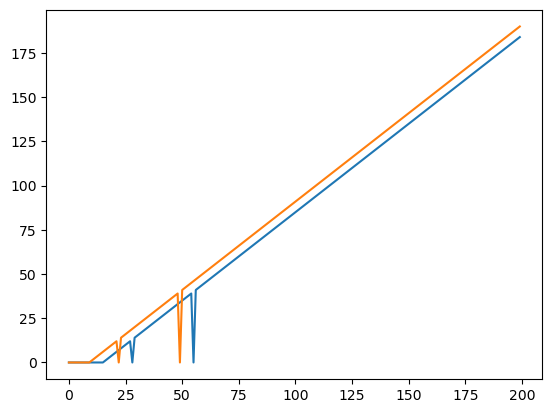

In [42]:
maxDelay = 15
circularBuffer = np.zeros(maxDelay)
d2 = 9
writeInd = 0
r1Ind = (writeInd-maxDelay)%maxDelay
r2Ind = (writeInd-d2)%maxDelay

r1Vals,r2Vals = [],[]
allBuffer = []
nIter = 200
for i in range(nIter):
    r1Vals.append(circularBuffer[r1Ind])
    r2Vals.append(circularBuffer[r2Ind])
    allBuffer.append(deepcopy(circularBuffer))

    if i in [13,40]:
        circularBuffer[writeInd] = 0
    else:
        circularBuffer[writeInd] = i
    writeInd = (writeInd+1)%maxDelay
    r1Ind = (writeInd-maxDelay)%maxDelay
    r2Ind = (writeInd-d2)%maxDelay

plt.plot(r1Vals)
plt.plot(r2Vals)
    
#need the read and write index for each neuron
#but because they are always the same distance apart, we just need to know one
#you read off i, write to i+1%len, then increase i each iteration
#we could implement nonuniform delays by having each synapse contain a read index
#thats not actually that expensive 
#but the neuron buffer would have to be as long as the longest delay 
#im not sure if this makes sense 
#need the write index and the neuron delay and the maximum delay 


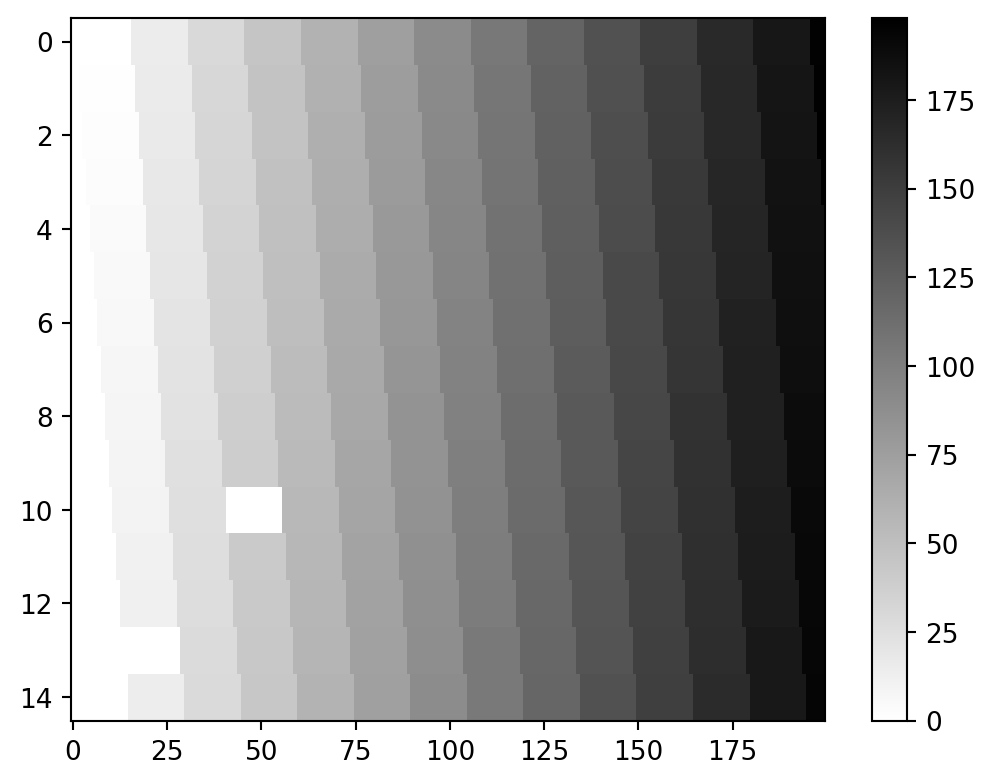

In [43]:
plt.figure(dpi=190)
plt.imshow(np.array(allBuffer).T,interpolation=None,cmap="binary")
plt.axis("auto")
plt.colorbar()